
Dataset: https://www.andyreiter.com/datasets/ 
https://www.usnews.com/best-colleges/rankings/national-universities 
https://nces.ed.gov/ipeds/datacenter/DataFiles.aspx?year=2024&sid=b6a4d888-22e4-45eb-b568-189d139610c2&rtid=1 (1st row dictionary and data)





In [6]:
#data 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")

UniversityRankings = UniversityRankings[['University Name','IPEDS','2027', '2026', '2025', '2024', '2023', '2022']]

Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

#There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 

#Converts all numbers to integers
years = ['2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')


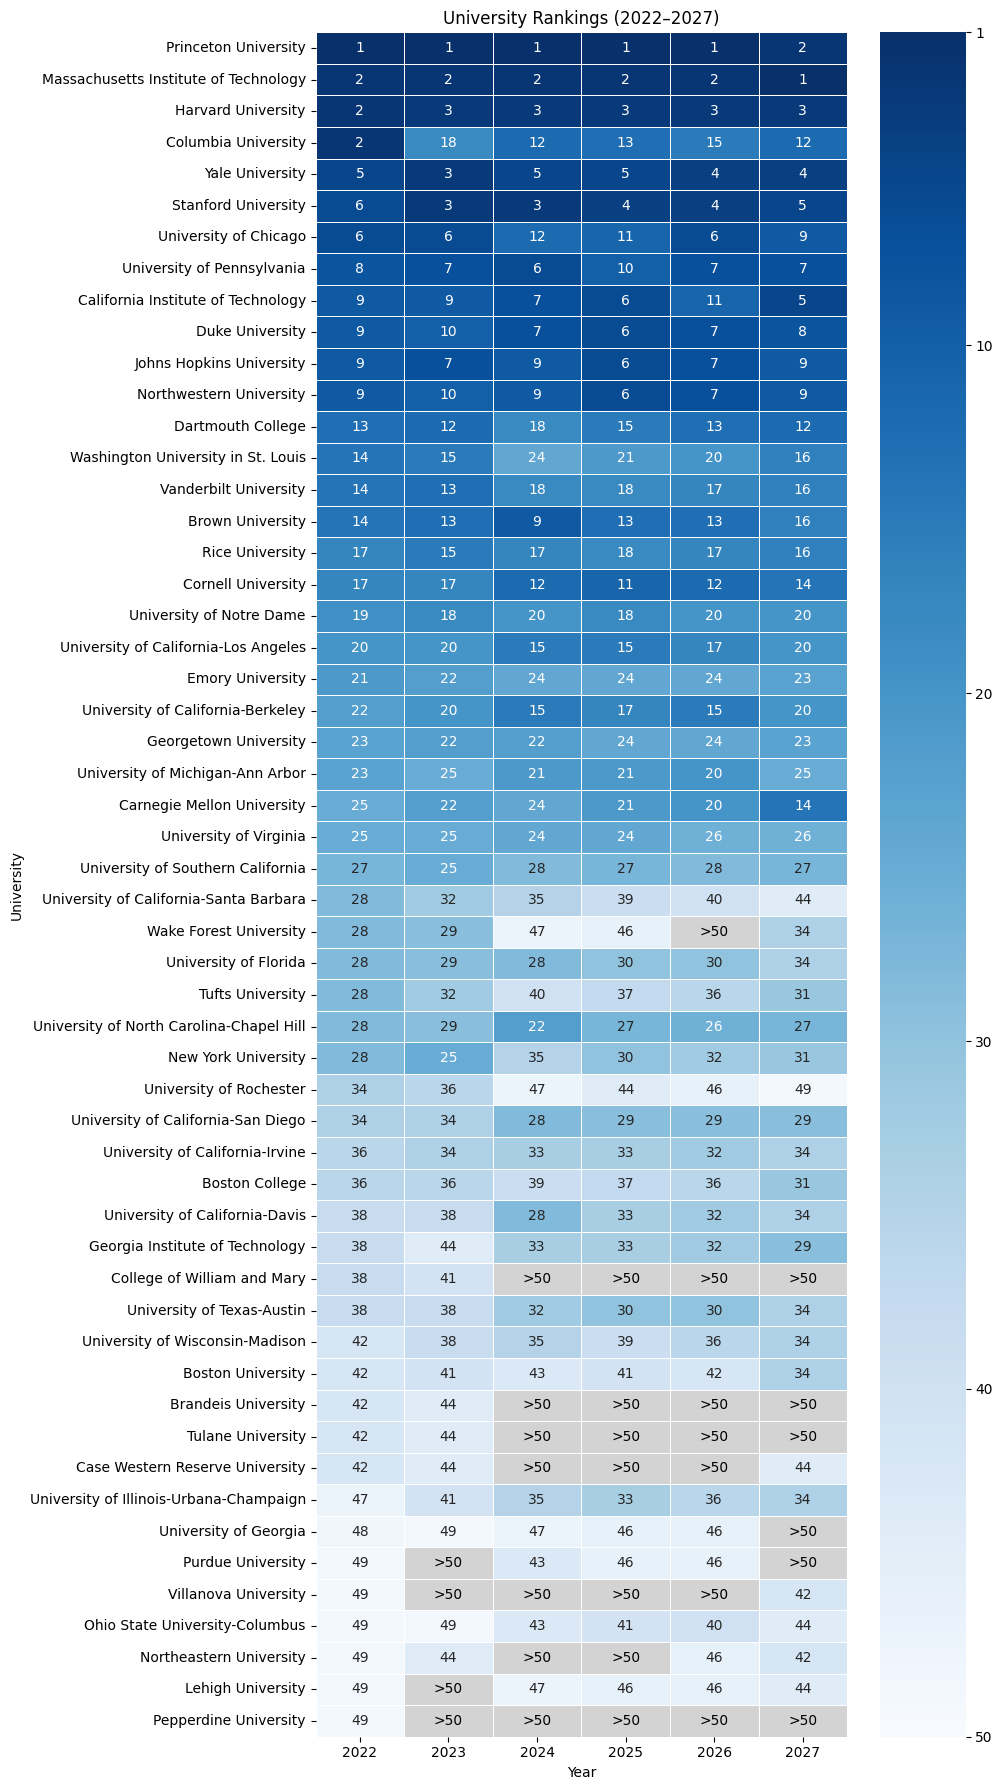

In [7]:
#top 50 universities highlighted 
heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2022')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

#Filters >50
labels = heatmap_data.copy()
labels = labels.map(lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else '')
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

plt.figure(figsize=(10, 18))
ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
)

#flips legend upsidown (1 on top)
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

ax.set_facecolor('lightgrey')
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')
            
plt.title('University Rankings (2022–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()







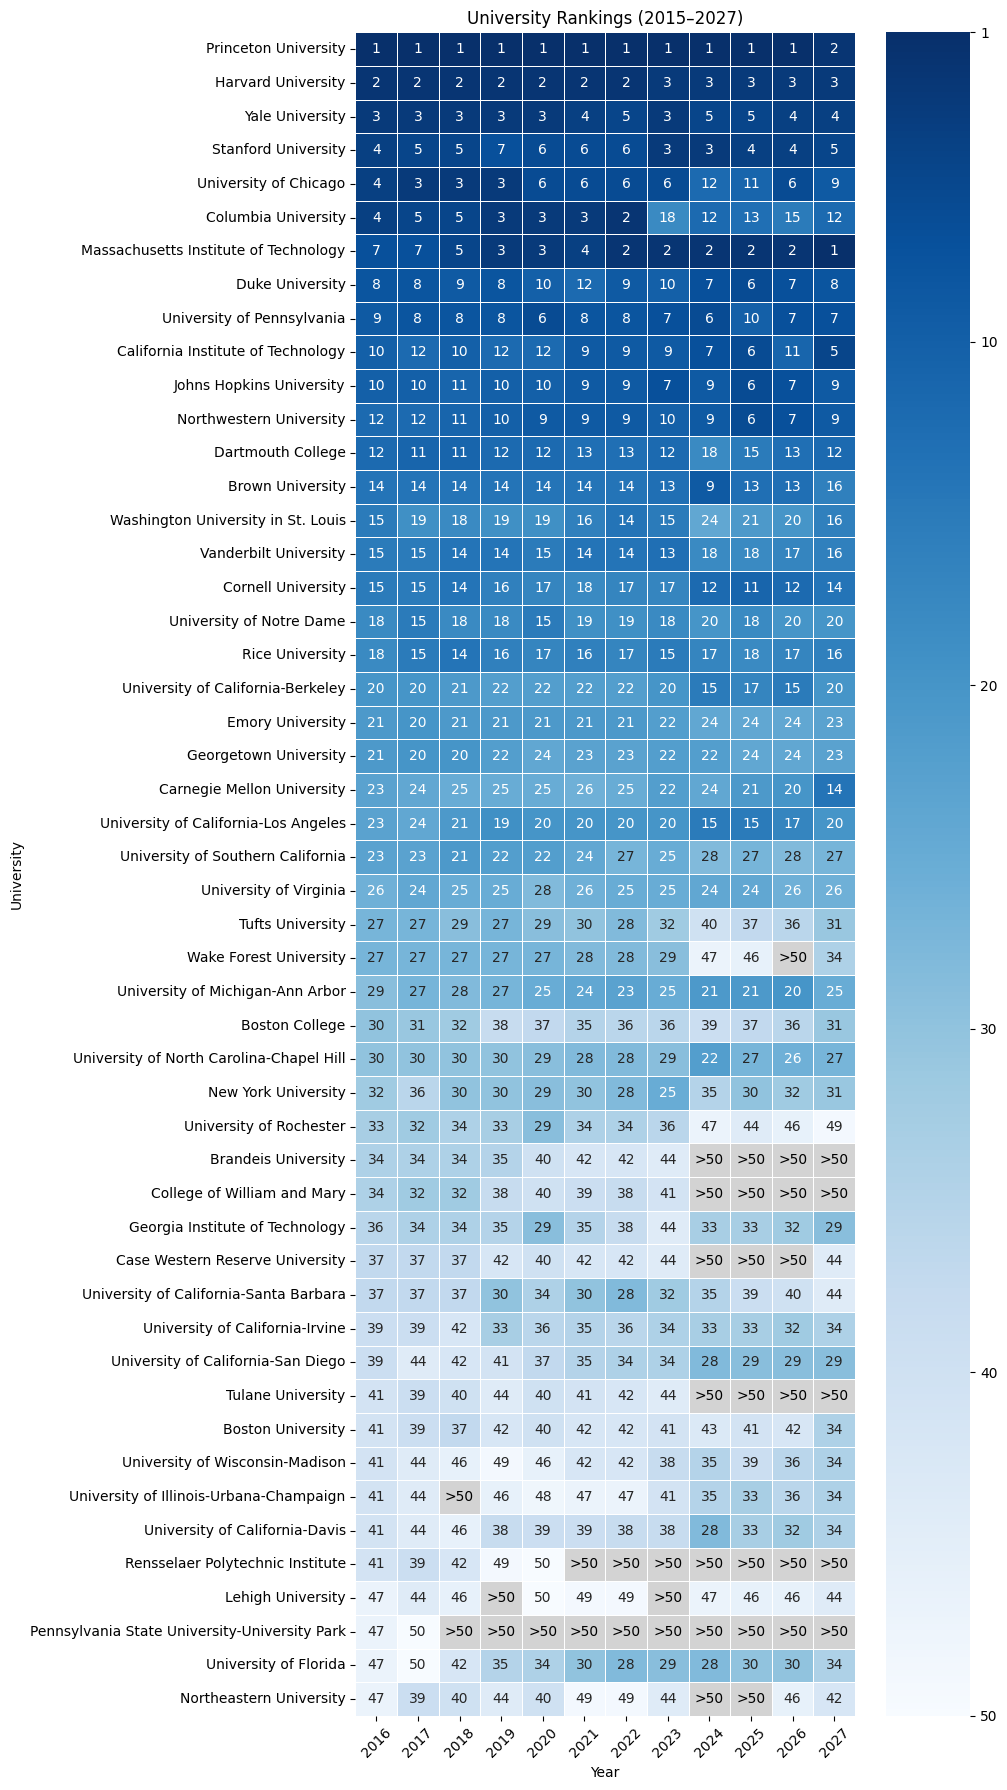

In [8]:
#data 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")

UniversityRankings = UniversityRankings[['University Name','IPEDS','2027', '2026', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016']]

Top50 = UniversityRankings[UniversityRankings['2016'] <= 50].copy()

#There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 

#Converts all numbers to integers
years = ['2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')

#top 50 universities highlighted 
heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2016')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

#Filters >50
labels = heatmap_data.copy()
labels = labels.map(lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else '')
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

plt.figure(figsize=(10, 18))
ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
)

#flips legend upsidown (1 on top)
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

ax.set_facecolor('lightgrey')
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')
            
plt.title('University Rankings (2015–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


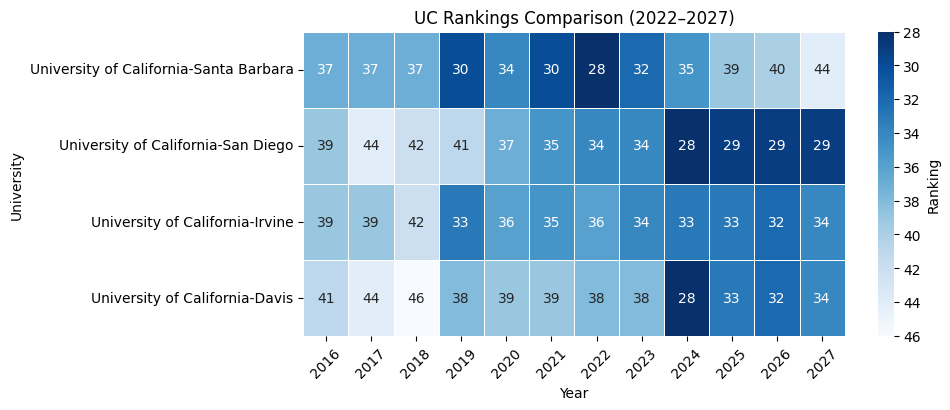

In [9]:
# UCSB, UCI, UCSD, and UCD highlighted 
UC_data = UniversityRankings[
    UniversityRankings['University Name'].str.contains(
        'University of California', case=False, na=False) &
    UniversityRankings['University Name'].str.contains(
        'Santa Barbara|Irvine|San Diego|Davis', case=False, na=False)
].copy()

UC_heatmap = UC_data.set_index('University Name')[years]
UC_heatmap = UC_heatmap.apply(pd.to_numeric, errors='coerce').astype(float)
UC_heatmap = UC_heatmap.sort_values('2022')

plt.figure(figsize=(10, 4))
sec = sns.heatmap(
    UC_heatmap,
    annot=True,
    fmt='.0f',
    cmap='Blues_r',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Ranking'}
)

cbar = sec.collections[0].colorbar
cbar.ax.invert_yaxis()

plt.title('UC Rankings Comparison (2022–2027)')
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.tight_layout()
plt.xticks(rotation = 45) 
plt.show()

In [17]:
ipeds = pd.read_csv("hd2024.csv")

#mannual search done to link private and public schools 
#discovered it was sorted in "control"

# Reload the original data to remove duplicate columns
UniversityRankings = pd.read_csv("UniversityRankings.csv")

ipeds = ipeds[['UNITID', 'INSTNM', 'CONTROL']].copy()

# Classify universities
ipeds['Type'] = ipeds['CONTROL'].map({
    1: 'Public',
    2: 'Private Nonprofit',
    3: 'Private For-Profit'
})

# Merge with all universities
UniversityRankings = UniversityRankings.merge(
    ipeds[['UNITID', 'Type']],
    left_on='IPEDS',
    right_on='UNITID',
    how='left',
    validate='many_to_one'
)


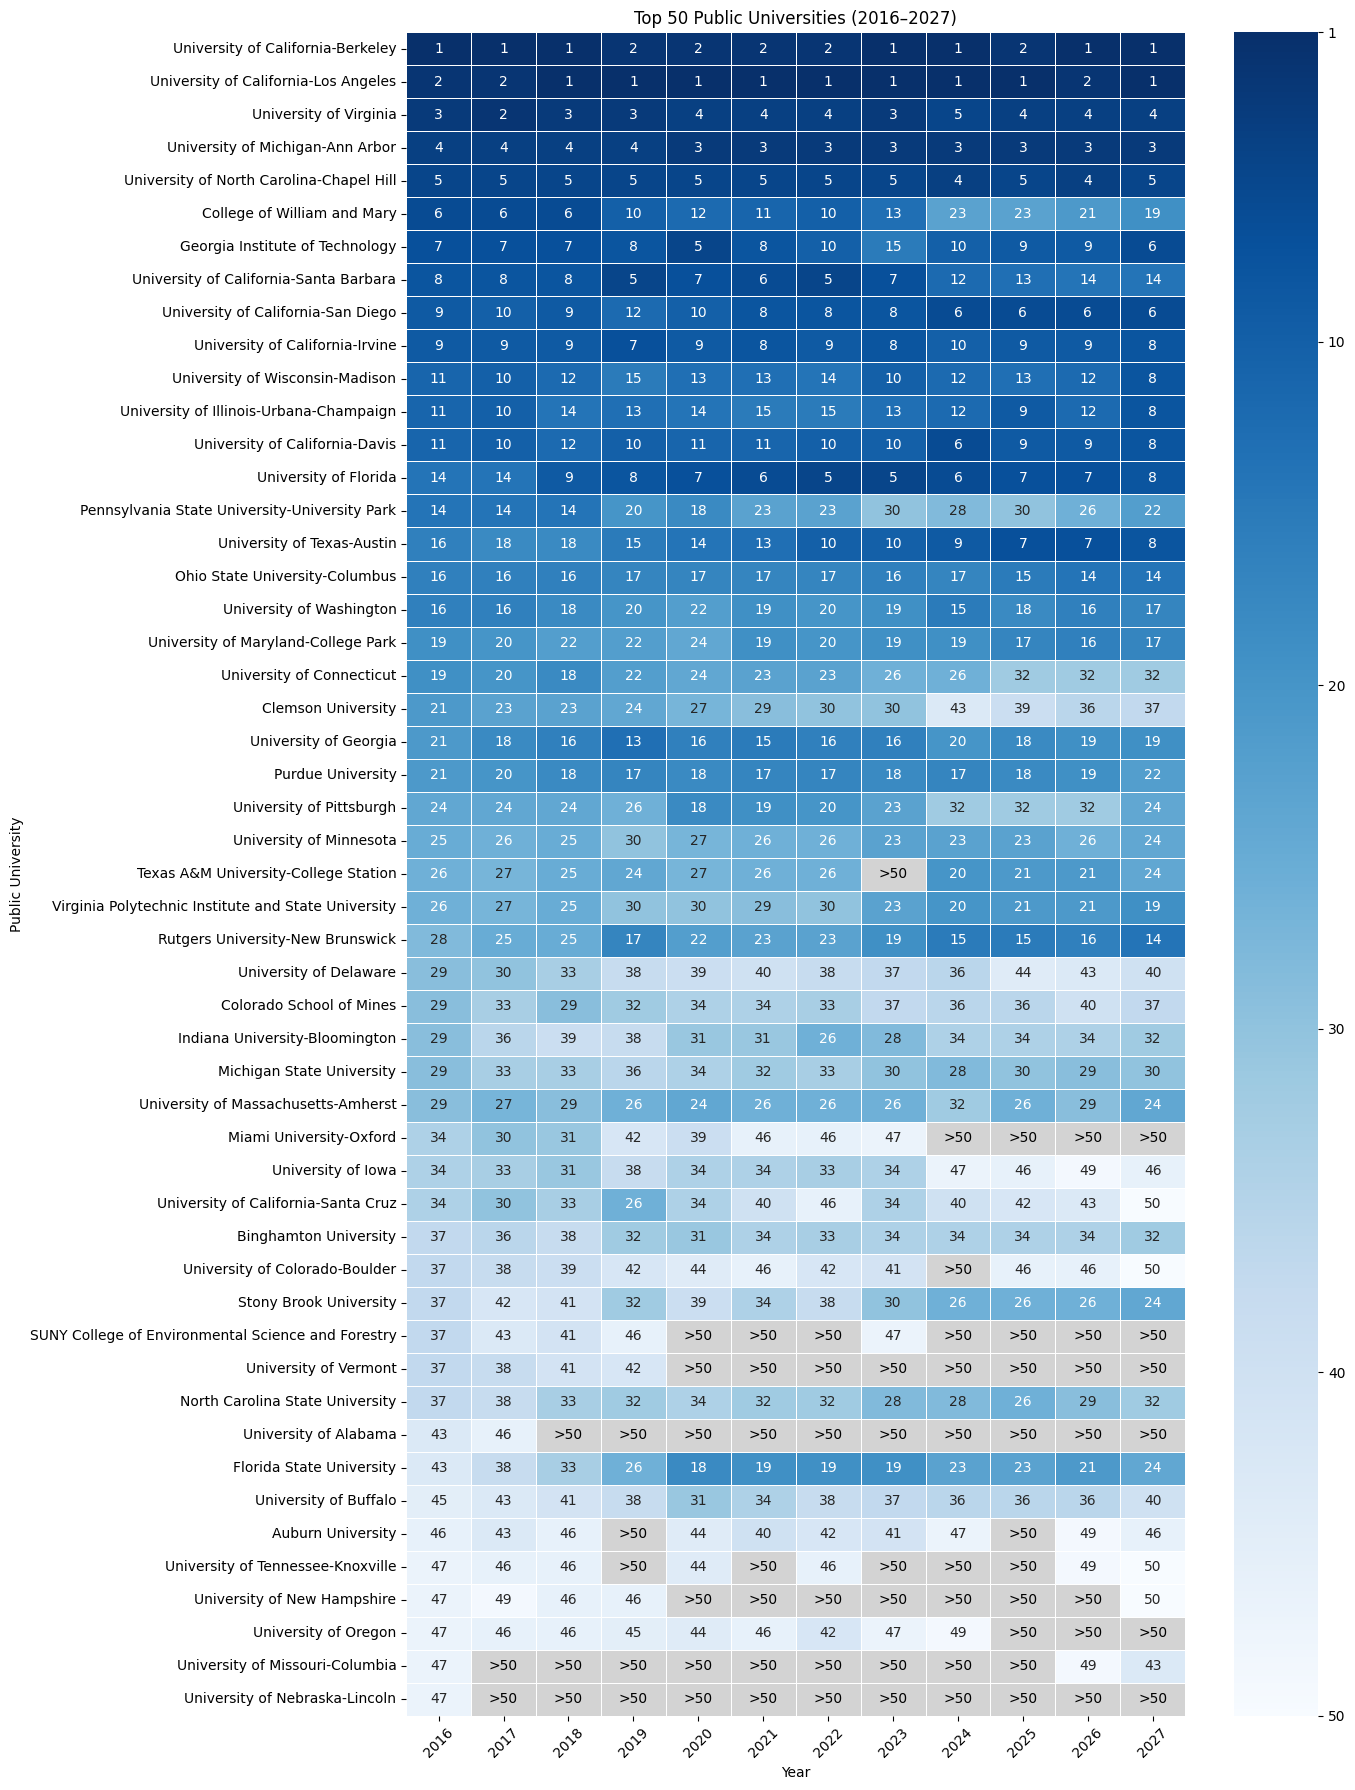

In [20]:
# Filter for public universities
Public = UniversityRankings[UniversityRankings['Type'] == 'Public'].copy()

years = ['2016', '2017', '2018', '2019', '2020',
         '2021', '2022', '2023', '2024', '2025',
         '2026', '2027']

# Convert rankings to numeric
Public[years] = Public[years].apply(pd.to_numeric, errors='coerce')

# Rank public universities separately for each year
# Universities tied nationally receive the same public ranking
Public[years] = Public[years].rank(method='min', ascending=True)

# Select top 50 public universities based on 2016
Top50Public = Public[Public['2016'] <= 50].copy()

# Prepare heatmap
heatmap_data = Top50Public[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2016')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

# Replace rankings greater than 50 with >50
labels = heatmap_data.map(
    lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else ''
)

# Only color rankings within the top 50
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

# Create heatmap
plt.figure(figsize=(14, 18))

ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5
)

 # Fill grey cells with >50
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[i, j]) or heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')

# Flip colorbar so rank 1 is on top
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

# Grey background for schools ranked >50
ax.set_facecolor('lightgrey')

plt.title('Top 50 Public Universities (2016–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('Public University')
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



                       mean  median  count
Type                                      
Private Nonprofit  1.694444     0.0     36
Public            -0.222222    -1.5     18


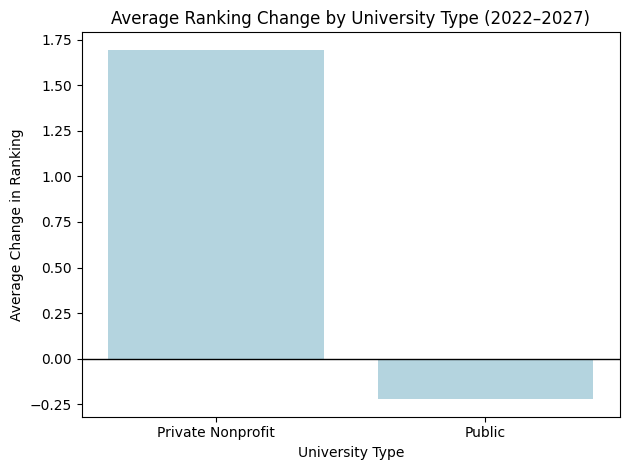

In [12]:
#private and public in top 50 changes 
Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

Top50['2022'] = pd.to_numeric(Top50['2022'], errors='coerce')
Top50['2027'] = pd.to_numeric(Top50['2027'], errors='coerce')
Top50['Ranking_Change'] = Top50['2027'] - Top50['2022']

comparison = Top50.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison)

avg_change = Top50.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Ranking Change by University Type (2022–2027)')
plt.xlabel('University Type')
plt.ylabel('Average Change in Ranking')
plt.tight_layout()
plt.show()

                       mean  median  count
Type                                      
Private Nonprofit  3.958333     1.5     72
Public            -4.455882    -4.0     68


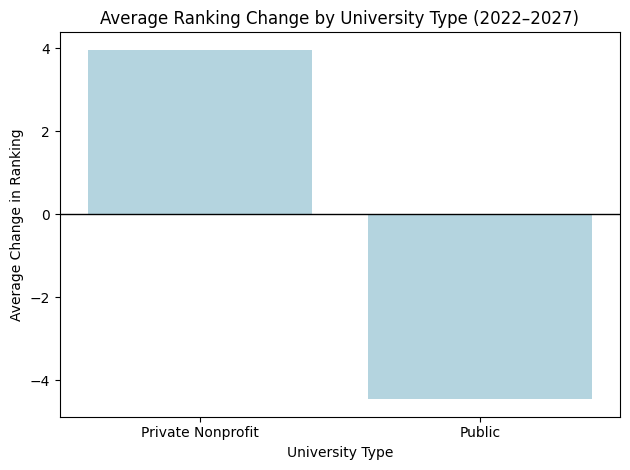

In [13]:
#private and public changes in all data 
UR = UniversityRankings.copy()

UR['2022'] = pd.to_numeric(UR['2022'], errors='coerce')
UR['2027'] = pd.to_numeric(UR['2027'], errors='coerce')
UR['Ranking_Change'] = UR['2027'] - UR['2022']

comparison2 = UR.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison2)

avg_change2 = UR.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change2,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Ranking Change by University Type (2022–2027)')
plt.xlabel('University Type')
plt.ylabel('Average Change in Ranking')
plt.tight_layout()
plt.show()

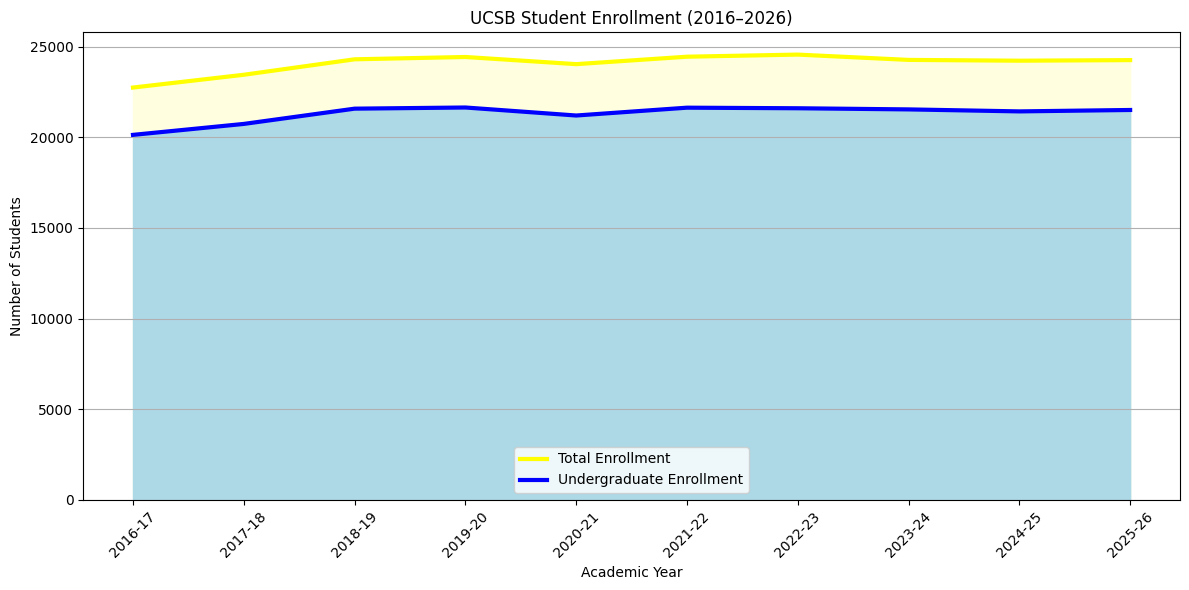

In [14]:
# https://bap.ucsb.edu/institutional-research/ucsb-information-center/enrollment-dashboard
 


import matplotlib.pyplot as plt
years = [
    "2016-17", "2017-18", "2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25", "2025-26"
]
undergrad = [
    20136, 20740, 21582, 21646, 21204, 21636, 21604, 21541, 21431, 21509
]
total = [
    22746, 23451, 24304, 24432, 24037, 24448, 24564, 24271, 24227, 24260
]

plt.figure(figsize=(12, 6))
plt.fill_between(years, total, color="lightyellow")
plt.fill_between(years, undergrad, color="lightblue")
plt.plot(years, total, color="yellow", linewidth=3, label="Total Enrollment")
plt.plot(years, undergrad, color="blue", linewidth=3, label="Undergraduate Enrollment")
plt.title("UCSB Student Enrollment (2016–2026)")
plt.xlabel("Academic Year")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

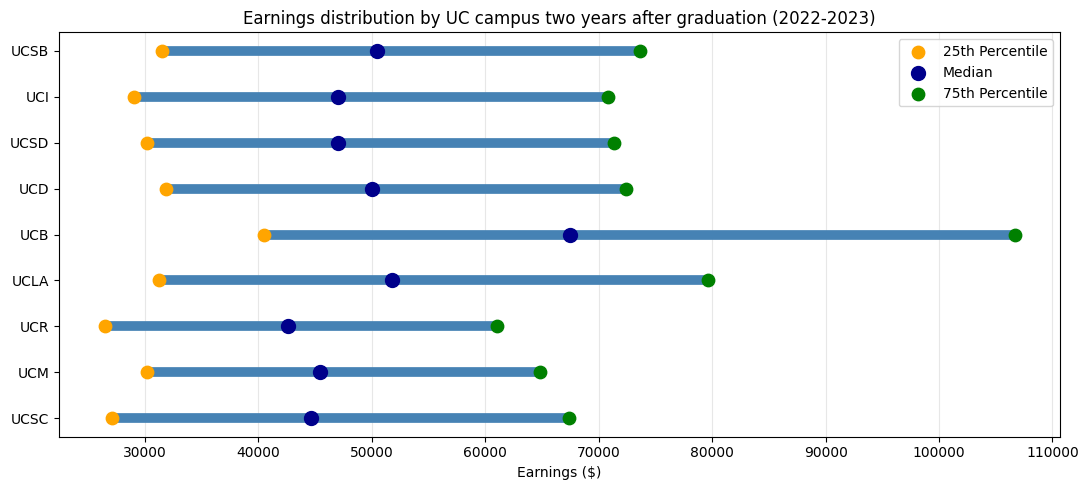

In [15]:
# https://www.universityofcalifornia.edu/about-uc/information-center/uc-alumni-work

import numpy as np 

UCSB = [31550, 50426, 73650]
UCI = [29024, 47074, 70842]
UCSD = [30227, 47048, 71381]
UCD = [31893, 49997, 72425]
UCB = [40488, 67434, 106659]
UCLA = [31223, 51754, 79645]
UCR = [26461, 42596, 61064]
UCM = [30240, 45484, 64816]
UCSC = [27125, 44636, 67372]
schools = ["UCSB", "UCI", "UCSD", "UCD", "UCB", "UCLA", "UCR", "UCM", "UCSC"]
data = [UCSB, UCI, UCSD, UCD, UCB, UCLA, UCR, UCM, UCSC]

p25 = [x[0] for x in data]
median = [x[1] for x in data]
p75 = [x[2] for x in data]

y = np.arange(len(schools))
plt.figure(figsize=(11, 5))
for i in range(len(schools)):
    plt.plot([p25[i], p75[i]], [y[i], y[i]],
             color="steelblue", linewidth=7,
             solid_capstyle="round")

plt.scatter(p25, y, color="orange", s=80,
            label="25th Percentile", zorder=3)
plt.scatter(median, y, color="darkblue", s=100,
            label="Median", zorder=3)
plt.scatter(p75, y, color="green", s=80,
            label="75th Percentile", zorder=3)
plt.yticks(y, schools)
plt.gca().invert_yaxis()
plt.xlabel("Earnings ($)")
plt.title("Earnings distribution by UC campus two years after graduation (2022-2023)")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

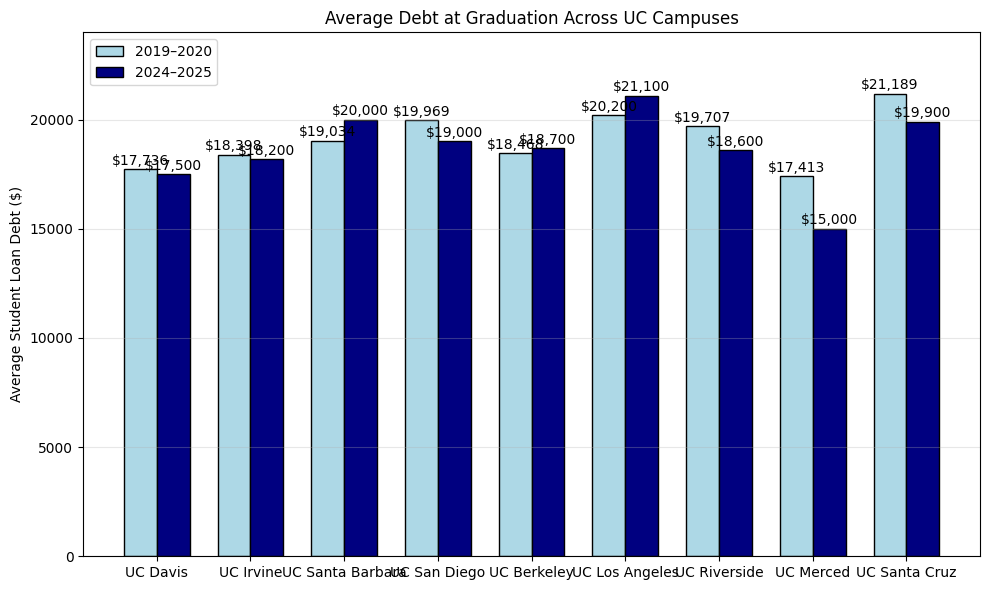

In [16]:
# https://accountability.universityofcalifornia.edu/2023/chapters/chapter-2.html
# https://accountability.universityofcalifornia.edu/2024/chapters/chapter-2.html
# https://www.universityofcalifornia.edu/about-uc/information-center/undergraduate-affordability#Comparativedebt




import matplotlib.pyplot as plt
import numpy as np

schools = ["UC Davis", "UC Irvine", "UC Santa Barbara", "UC San Diego", "UC Berkeley", "UC Los Angeles", "UC Riverside", "UC Merced", "UC Santa Cruz"]

# 2019–2020 graduating cohort
debt_2020 = [17736, 18398, 19034, 19969, 18468, 20200, 19707, 17413, 21189]

# 2024–2025: rounded values visible in the newer chart
# Replace missing values when verified
debt_2025 = [17500, 18200, 20000, 19000, 18700, 21100, 18600, 15000, 19900]

x = np.arange(len(schools))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2, debt_2020, width,
    label="2019–2020", color="lightblue", edgecolor="black"
)

bars2 = plt.bar(
    x + width/2, debt_2025, width,
    label="2024–2025", color="navy", edgecolor="black"
)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if np.isfinite(height):
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height + 200,
                f"${height:,.0f}",
                ha="center",
                fontsize=10
            )

plt.xticks(x, schools)
plt.ylabel("Average Student Loan Debt ($)")
plt.title("Average Debt at Graduation Across UC Campuses")
plt.ylim(0, 24000)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


